# 04 - Model experiments
Five model families are trained and compared with group-aware cross-validation on the **training** trips
(80), then evaluated on the **student-testing** trips. Primary selection metric: **cross-validation
macro F1** (candidate level, top-1 decision), with log loss and route continuity as secondary checks.
The best model is then tuned with Bayesian optimisation.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt

OUT, GRAPHS, MAPS = ROOT / "outputs", ROOT / "outputs" / "graphs", ROOT / "outputs" / "maps"
PROC = ROOT / "dataset" / "processed"
for d in (GRAPHS, MAPS, PROC, ROOT / "models" / "configurations"):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200, "display.max_columns", 40)

In [2]:
import time, json, joblib
from src import data_loader as dl
from src.evaluation import (group_cv, fit_model, predict_proba_1, observation_metrics, subsample_by_obs,
                            predicted_arc_per_obs, pooled_route_continuity)
from src.feature_engineering import FEATURE_COLUMNS, load_dataset
from src.models import MODELS, get_model
from src.road_network import RoadNetwork

SEED = 42
CV_FOLDS = 5
CV_ROW_CAP = 400_000     # max training rows per CV fold (whole observations), same for every model
N_TRIALS = 30            # Bayesian optimisation trials

tr_c, tr_o, CFG = load_dataset(PROC / "training_features.joblib")
st_c, st_o, _ = load_dataset(PROC / "student_testing_features.joblib")
scaler = joblib.load(ROOT / "models" / "scaler.pkl")
Xtr = scaler.transform(tr_c[FEATURE_COLUMNS]).astype(np.float32)
Xst = scaler.transform(st_c[FEATURE_COLUMNS]).astype(np.float32)
st_nets = {}
for t in dl.list_trips("student_testing"):
    _trip = dl.load_trip("student_testing", t, with_route=False)
    st_nets[int(t)] = RoadNetwork(_trip.nodes, _trip.arcs)
print(Xtr.shape, Xst.shape, "| trips:", tr_c.group.nunique(), "train /", st_c.group.nunique(), "student-test")

(1323496, 19) (140944, 19) | trips: 80 train / 10 student-test


## 1. Non-learning reference: nearest candidate

In [3]:
nearest = observation_metrics(st_c, st_o, -st_c["dist_m"].to_numpy())
print({k: round(v, 4) for k, v in nearest.items() if k in ("top1_acc", "macro_f1", "precision_pos", "recall_pos")})

{'top1_acc': 0.5398, 'macro_f1': 0.7344, 'precision_pos': 0.5409, 'recall_pos': 0.5409}


## 2. Train, cross-validate and test every model

In [12]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.


In [13]:
def cap_for(mod):
    caps = [c for c in (mod.MAX_TRAIN_ROWS, CV_ROW_CAP) if c is not None]
    return min(caps) if caps else None

train_eval_rows = subsample_by_obs(tr_c, tr_c.has_ref.to_numpy(), 150_000, SEED)   # for the train-set score
tr_eval_c, tr_eval_o = tr_c.iloc[train_eval_rows], tr_o[tr_o.obs_key.isin(tr_c.obs_key.to_numpy()[train_eval_rows])]

def run_experiment(name, params=None):
    """CV on training trips + final fit + student-test evaluation, all with identical settings."""
    mod = get_model(name); params = params or {}
    build = lambda: mod.build(**params)
    cv = group_cv(build, Xtr, tr_c, tr_o, n_splits=CV_FOLDS, seed=SEED, max_train_rows=cap_for(mod))
    fit_rows = subsample_by_obs(tr_c, tr_c.has_ref.to_numpy(), mod.MAX_TRAIN_ROWS, SEED)
    model, fit_s = fit_model(build, Xtr, tr_c, fit_rows)
    t0 = time.perf_counter(); p = predict_proba_1(model, Xst); pred_s = time.perf_counter() - t0
    st = observation_metrics(st_c, st_o, p)
    tr = observation_metrics(tr_eval_c, tr_eval_o, predict_proba_1(model, Xtr[train_eval_rows]))
    arcs = predicted_arc_per_obs(st_c, p, st_o)
    cont = pooled_route_continuity(arcs, st_o, st_nets)
    row = {"model": name, "family": mod.FAMILY, "config": json.dumps({**mod.DEFAULT_PARAMS, **params}),
           "cv_macro_f1": cv.macro_f1.mean(), "cv_macro_f1_std": cv.macro_f1.std(),
           "cv_top1_acc": cv.top1_acc.mean(), "cv_log_loss": cv.log_loss.mean(),
           "train_top1_acc": tr["top1_acc"], "train_macro_f1": tr["macro_f1"], "train_log_loss": tr["log_loss"],
           "student_top1_acc": st["top1_acc"], "student_macro_f1": st["macro_f1"], "student_log_loss": st["log_loss"],
           "student_precision": st["precision_pos"], "student_recall": st["recall_pos"],
           "student_candidate_miss": st["candidate_miss_rate"], "route_continuity": cont["route_continuity"],
           "fit_seconds": fit_s, "inference_ms_per_1k_obs": 1000 * 1000 * pred_s / len(st_o)}
    return row, cv, model, p

results, cv_tables, student_proba = [], {}, {}
for name, mod in MODELS.items():
    try:
        mod.build()
    except ImportError as e:
        print(f"SKIPPED {name}: {e}  (install it from requirements.txt)"); continue
    t0 = time.time()
    row, cv, model, p = run_experiment(name)
    results.append(row); cv_tables[name] = cv.assign(model=name); student_proba[name] = p
    np.save(PROC / f"student_proba_{name}.npy", p)
    print(f"{name:20s} cv F1 {row['cv_macro_f1']:.4f} (+-{row['cv_macro_f1_std']:.4f})  student top-1 {row['student_top1_acc']:.4f}"
          f"  F1 {row['student_macro_f1']:.4f}  logloss {row['student_log_loss']:.4f}  ({time.time() - t0:.0f}s)")
comp = pd.DataFrame(results)
pd.concat(cv_tables.values()).to_csv(OUT / "cv_fold_results.csv", index=False)

logistic_regression  cv F1 0.9186 (+-0.0181)  student top-1 0.8545  F1 0.9168  logloss 0.1250  (11s)
knn                  cv F1 0.9160 (+-0.0195)  student top-1 0.8505  F1 0.9145  logloss 0.1861  (293s)
decision_tree        cv F1 0.9229 (+-0.0174)  student top-1 0.8683  F1 0.9248  logloss 0.0952  (48s)
random_forest        cv F1 0.9254 (+-0.0180)  student top-1 0.8715  F1 0.9266  logloss 0.0862  (158s)
xgboost              cv F1 0.9264 (+-0.0166)  student top-1 0.8832  F1 0.9335  logloss 0.0819  (70s)


In [14]:
comp.to_csv(OUT / "model_comparison_full.csv", index=False)
# table in the layout requested by the report template
report = pd.DataFrame({
    "Model": comp.model, "Algorithm family": comp.family, "Key configuration": comp.config,
    "CV macro F1": comp.cv_macro_f1.round(4), "Top-1 accuracy (student)": comp.student_top1_acc.round(4),
    "Route continuity": comp.route_continuity.round(4), "Student-test macro F1": comp.student_macro_f1.round(4),
    "Log loss": comp.student_log_loss.round(4), "Inference ms / 1k obs": comp.inference_ms_per_1k_obs.round(1)})
report.to_csv(OUT / "model_comparison.csv", index=False)
report

,Model,Algorithm family,Key configuration,CV macro F1,Top-1 accuracy (student),Route continuity,Student-test macro F1,Log loss,Inference ms / 1k obs
0,logistic_regression,Linear / probabilistic,"{""C"": 1.0, ""max_iter"": 300, ""solver"": ""lbfgs"",...",0.9186,0.8545,0.7093,0.9168,0.1250,0.2
1,knn,Instance-based,"{""n_neighbors"": 25, ""weights"": ""uniform"", ""p"": 2}",0.9160,0.8505,0.7156,0.9145,0.1861,1159.9
2,decision_tree,Tree-based,"{""max_depth"": 10, ""min_samples_leaf"": 50, ""cri...",0.9229,0.8683,0.7356,0.9248,0.0952,0.5
3,random_forest,Ensemble (bagging),"{""n_estimators"": 100, ""max_depth"": 14, ""min_sa...",0.9254,0.8715,0.7315,0.9266,0.0862,12.8
4,xgboost,Boosting,"{""n_estimators"": 300, ""max_depth"": 6, ""learnin...",0.9264,0.8832,0.7641,0.9335,0.0819,10.7


## 3. Over/under-fitting evidence: train vs CV vs student-test

In [15]:
comp[["model", "train_top1_acc", "cv_top1_acc", "student_top1_acc", "train_macro_f1", "cv_macro_f1", "student_macro_f1",
      "train_log_loss", "cv_log_loss", "student_log_loss"]].round(4)

,model,train_top1_acc,cv_top1_acc,student_top1_acc,train_macro_f1,cv_macro_f1,student_macro_f1,train_log_loss,cv_log_loss,student_log_loss
0,logistic_regression,0.8656,0.7728,0.8545,0.9215,0.9186,0.9168,0.1347,0.1379,0.1250
1,knn,0.8823,0.7692,0.8505,0.9312,0.9160,0.9145,0.0926,0.2370,0.1861
2,decision_tree,0.8871,0.7796,0.8683,0.9341,0.9229,0.9248,0.0878,0.1204,0.0952
3,random_forest,0.8938,0.7834,0.8715,0.9379,0.9254,0.9266,0.0759,0.0949,0.0862
4,xgboost,0.9241,0.7847,0.8832,0.9557,0.9264,0.9335,0.0632,0.0953,0.0819


## 4. Training curves (only for models that produce them: XGBoost)

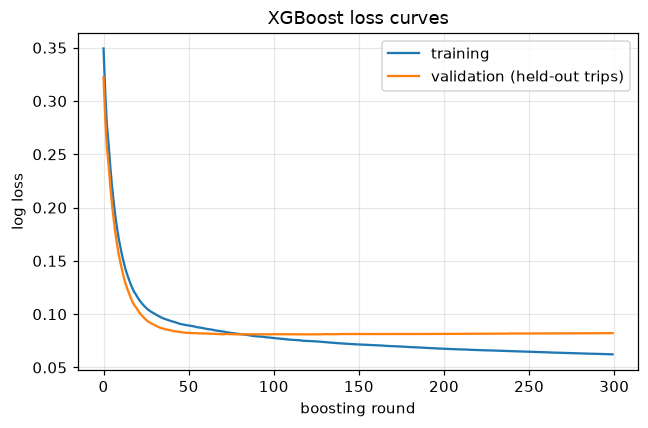

In [16]:
try:
    from xgboost import XGBClassifier
    val_trips = np.random.default_rng(SEED).choice(tr_c.group.unique(), size=max(2, tr_c.group.nunique() // 5), replace=False)
    is_val = tr_c.group.isin(val_trips).to_numpy(); lab = tr_c.has_ref.to_numpy()
    xm = get_model("xgboost").build()
    xm.fit(Xtr[~is_val & lab], tr_c.y.to_numpy()[~is_val & lab],
           eval_set=[(Xtr[~is_val & lab], tr_c.y.to_numpy()[~is_val & lab]), (Xtr[is_val & lab], tr_c.y.to_numpy()[is_val & lab])], verbose=False)
    hist = xm.evals_result()
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(hist["validation_0"]["logloss"], label="training"); ax.plot(hist["validation_1"]["logloss"], label="validation (held-out trips)")
    ax.set(xlabel="boosting round", ylabel="log loss", title="XGBoost loss curves"); ax.legend(); fig.tight_layout()
    fig.savefig(GRAPHS / "xgboost_loss_curves.png"); plt.show()
except ImportError:
    print("xgboost not installed - skipped")

## 5. Model selection

In [ ]:
best_row = comp.sort_values(["cv_macro_f1", "cv_log_loss"], ascending=[False, True]).iloc[0]
best_name = "xgboost"
print("selected for tuning:", best_name, "| cv macro F1 = %.4f" % best_row.cv_macro_f1)
comp.sort_values("cv_macro_f1", ascending=False)[["model", "cv_macro_f1", "cv_macro_f1_std", "student_top1_acc", "student_macro_f1",
                                                    "student_log_loss", "route_continuity", "fit_seconds", "inference_ms_per_1k_obs"]].round(4)

selected for tuning: random_forest | cv macro F1 = 0.9254


,model,cv_macro_f1,cv_macro_f1_std,student_top1_acc,student_macro_f1,student_log_loss,route_continuity,fit_seconds,inference_ms_per_1k_obs
3,random_forest,0.9254,0.0180,0.8715,0.9266,0.0862,0.7315,37.8405,13.9349
2,decision_tree,0.9229,0.0174,0.8683,0.9248,0.0952,0.7356,21.6017,0.4919
0,logistic_regression,0.9186,0.0181,0.8545,0.9168,0.1250,0.7093,4.2143,0.3376
1,knn,0.9160,0.0195,0.8505,0.9145,0.1861,0.7156,0.0196,1560.5757


## 6. Bayesian hyperparameter optimisation (Optuna TPE, group-aware CV on training trips)
Objective: mean CV macro F1 (3 group folds). The student-testing trips are not used in the search.

In [10]:
%pip install optuna

  Using cached optuna-5.1.0-py3-none-any.whl.metadata (15 kB)
  Using cached colorlog-6.12.0-py3-none-any.whl.metadata (11 kB)
Using cached optuna-5.1.0-py3-none-any.whl (442 kB)
Using cached colorlog-6.12.0-py3-none-any.whl (12 kB)

   ---------- ----------------------------- 1/4 [colorlog]
   -------------------- ------------------- 2/4 [alembic]
   -------------------- ------------------- 2/4 [alembic]
   ------------------------------ --------- 3/4 [optuna]
   ------------------------------ --------- 3/4 [optuna]
   ------------------------------ --------- 3/4 [optuna]
   ------------------------------ --------- 3/4 [optuna]
   ------------------------------ --------- 3/4 [optuna]
   ---------------------------------------- 4/4 [optuna]

Note: you may need to restart the kernel to use updated packages.


In [23]:
from src.optimisation.bayes_gpu import optimise_gpu, DEVICE
print("device:", DEVICE)   # must say cuda
best_params, best_f1, trials = optimise_gpu(
    Xtr, tr_c, tr_o, n_trials=30, n_splits=3, seed=42, max_train_rows=400_000,
    out_dir=OUT, model_dir=ROOT / "models" / "configurations")

device: cuda
trial   0 | device=cuda | cv macro F1=0.9285 |   41.1s | {'n_estimators': 287, 'max_depth': 10, 'learning_rate': 0.1205712628744377, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.5780093202212182, 'min_child_weight': 1.5957084694148351, 'reg_lambda': 0.01555019165426488}
trial   1 | device=cuda | cv macro F1=0.9276 |   48.2s | {'n_estimators': 533, 'max_depth': 7, 'learning_rate': 0.11114989443094977, 'subsample': 0.5102922471479012, 'colsample_bytree': 0.9849549260809971, 'min_child_weight': 12.10689693600216, 'reg_lambda': 0.05022706182399988}
trial   2 | device=cuda | cv macro F1=0.9247 |   12.0s | {'n_estimators': 191, 'max_depth': 4, 'learning_rate': 0.028145092716060652, 'subsample': 0.762378215816119, 'colsample_bytree': 0.7159725093210578, 'min_child_weight': 2.3927528765580632, 'reg_lambda': 1.0465133152078552}
trial   3 | device=cuda | cv macro F1=0.9262 |   11.2s | {'n_estimators': 169, 'max_depth': 5, 'learning_rate': 0.03476649150592621, 'subsample': 

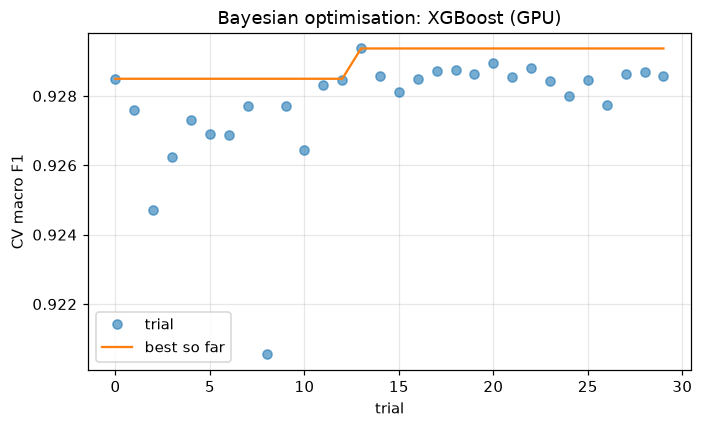

In [25]:
t = trials.rename(columns={"number": "trial", "value": "cv_macro_f1"})

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(t["trial"], t["cv_macro_f1"], "o", alpha=.6, label="trial")
ax.plot(t["trial"], t["cv_macro_f1"].cummax(), "-", label="best so far")
ax.set(xlabel="trial", ylabel="CV macro F1", title="Bayesian optimisation: XGBoost (GPU)")
ax.legend(); fig.tight_layout()
fig.savefig(GRAPHS / "optimisation_history.png"); plt.show()

## 7. Untuned vs tuned (identical CV settings and student-testing trips)

In [27]:
t.sort_values("cv_macro_f1", ascending=False).head(10).round(4)
tuned_row, tuned_cv, tuned_model, tuned_p = run_experiment(best_name, best_params)
base_row = comp[comp.model == best_name].iloc[0].to_dict()
cmp_cols = ["cv_macro_f1", "student_top1_acc", "student_macro_f1", "student_log_loss", "route_continuity", "inference_ms_per_1k_obs", "fit_seconds"]
tune_cmp = pd.DataFrame({"untuned": {c: base_row[c] for c in cmp_cols}, "tuned": {c: tuned_row[c] for c in cmp_cols}})
tune_cmp["change"] = tune_cmp.tuned - tune_cmp.untuned
tune_cmp.to_csv(OUT / "tuned_vs_untuned.csv"); tune_cmp.round(4)

TypeError: RandomForestClassifier.__init__() got an unexpected keyword argument 'learning_rate'

## 8. Export the final model and configuration

In [ ]:
# keep the tuned model only if it is not worse on CV macro F1; otherwise keep the untuned configuration
use_tuned = tuned_row["cv_macro_f1"] >= base_row["cv_macro_f1"]
final_params = best_params if use_tuned else {}
final_mod = get_model(best_name)
fit_rows = subsample_by_obs(tr_c, tr_c.has_ref.to_numpy(), final_mod.MAX_TRAIN_ROWS, SEED)
final_model, _ = fit_model(lambda: final_mod.build(**final_params), Xtr, tr_c, fit_rows)
joblib.dump(final_model, ROOT / "models" / "final_model.pkl")
from src.route_reconstruction.hmm import HMMConfig
cfg = {"model_name": best_name, "model_params": final_params, "used_tuned_params": bool(use_tuned),
       "feature_columns": FEATURE_COLUMNS, "feature_config": CFG.to_dict(),
       "hmm_config": HMMConfig().to_dict(), "seed": SEED}
json.dump(cfg, open(ROOT / "models" / "configurations" / "pipeline_config.json", "w"), indent=2)
json.dump({n: {"family": m.FAMILY, "default_params": m.DEFAULT_PARAMS, "max_train_rows": m.MAX_TRAIN_ROWS} for n, m in MODELS.items()},
          open(ROOT / "models" / "configurations" / "model_configs.json", "w"), indent=2)
json.dump({"seed": SEED, "cv_folds": CV_FOLDS, "cv_row_cap": CV_ROW_CAP, "n_trials": N_TRIALS, "optimisation_seconds": opt_seconds,
           "selected_model": best_name, "used_tuned_params": bool(use_tuned)}, open(OUT / "experiment_log.json", "w"), indent=2)
print("saved final model:", best_name, "| tuned params used:", use_tuned)